# Heart Disease Patient Analysis
### A data analyst portfolio project · Python (pandas) → Power BI → PowerPoint

**Scenario.** A hospital cardiology department has records for 303 patients who were checked for heart disease. Management wants to use the data to improve **screening, triage and the use of diagnostic tests**. This notebook answers the department's 10 business questions.

**Data.** The data is the UCI Cleveland heart disease dataset, Kaggle version (`data/raw/heart-disease.csv`).

**Tools.** The notebook uses pandas, NumPy, Matplotlib, Seaborn and SciPy. The cleaned output feeds a Power BI dashboard and a presentation.

---

### The 10 business problems

| # | Business problem | Why the business cares |
|---|---|---|
| 1 | **Can we trust the data?** Is it complete, valid and correctly labelled? | Decisions built on wrong labels are wrong decisions |
| 2 | **How big is the problem?** What share of patients have heart disease, and who are they? | Capacity planning and the baseline for every other comparison |
| 3 | **Which age groups are most affected?** | Decide the age at which to start screening |
| 4 | **Do men and women differ?** | Gender-targeted awareness and screening |
| 5 | **Can chest-pain type triage patients?** | Faster, cheaper triage at first contact |
| 6 | **Do routine checks (BP, cholesterol, blood sugar, ECG) separate patients?** | Whether cheap tests can act as a filter |
| 7 | **How useful is the exercise stress test?** | Value of a mid-cost test |
| 8 | **How useful are imaging tests (fluoroscopy, thallium scan)?** | Value of expensive tests and where to use them |
| 9 | **Which factors matter most overall?** | Where to put the diagnostic budget |
| 10 | **Can we segment patients into risk tiers?** | Prioritise follow-up appointments |

### Process
1. Setup → 2. Load and first look → 3. **Validate and clean** (Problem 1) → 4. Feature engineering → 5. Analysis (Problems 2–10) → 6. Export for Power BI → 7. Summary of findings

## 1. Setup
Import the libraries, set the folder paths and define the chart colours used throughout the project.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Folder paths (the notebook lives in /notebooks)
ROOT = Path("..")
RAW_FILE = ROOT / "data" / "raw" / "heart-disease.csv"
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

# One colour per outcome, used in every chart
DISEASE, NO_DISEASE, GREY = "#C8102E", "#5B7083", "#9A9A9A"
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.max_columns", 40)

Two helper functions keep the analysis short. `rate_table` turns any column into a summary table, and `plot_rate` draws that table as a bar chart.

In [2]:
def rate_table(data, col):
    """Patients, patients with heart disease and the disease rate (%) for each group in `col`."""
    t = data.groupby(col, observed=True)["heart_disease"].agg(patients="count", with_disease="sum")
    t["disease_rate_%"] = (t["with_disease"] / t["patients"] * 100).round(1)
    return t


def save(fig, name):
    """Save a chart to /images (used by the README and the slides), then show it."""
    fig.tight_layout()
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_rate(t, title, xlabel, name, ax=None, show_overall=True):
    """Bar chart of the disease rate per group, labelled with rate and patient count."""
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(t.index.astype(str), t["disease_rate_%"], color=DISEASE, width=0.6)
    for bar, rate, n in zip(bars, t["disease_rate_%"], t["patients"]):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 2, f"{rate:.0f}%\n(n={n})",
                ha="center", va="bottom", fontsize=9)
    if show_overall:
        ax.axhline(OVERALL_RATE, ls="--", lw=1, color=GREY)
        ax.text(0.01, 0.97, f"- - overall rate {OVERALL_RATE:.0f}%", transform=ax.transAxes, ha="left", va="top", color=GREY, fontsize=9)
    ax.set(ylim=(0, 115), ylabel="Patients with heart disease (%)", xlabel=xlabel, title=title)
    if own_fig:
        save(ax.figure, name)

## 2. Load the data and take a first look

In [3]:
raw = pd.read_csv(RAW_FILE)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

303 rows x 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
raw.describe().round(1)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0
mean,54.4,0.7,1.0,131.6,246.3,0.1,0.5,149.6,0.3,1.0,1.4,0.7,2.3,0.5
std,9.1,0.5,1.0,17.5,51.8,0.4,0.5,22.9,0.5,1.2,0.6,1.0,0.6,0.5
min,29.0,0.0,0.0,94.0,126.0,0.0,0.0,71.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,47.5,0.0,0.0,120.0,211.0,0.0,0.0,133.5,0.0,0.0,1.0,0.0,2.0,0.0
50%,55.0,1.0,1.0,130.0,240.0,0.0,1.0,153.0,0.0,0.8,1.0,0.0,2.0,1.0
75%,61.0,1.0,2.0,140.0,274.5,0.0,1.0,166.0,1.0,1.6,2.0,1.0,3.0,1.0
max,77.0,1.0,3.0,200.0,564.0,1.0,2.0,202.0,1.0,6.2,2.0,4.0,3.0,1.0


Every column is numeric, including the categories, which are stored as codes such as `cp = 0..3`. Before analysing anything, we need to be sure what those codes mean.

## 3. Business Problem 1: Can we trust the data?
We check four things:
1. **Completeness**: are there missing values?
2. **Uniqueness**: are there duplicate patients?
3. **Validity**: are all codes inside their documented range?
4. **Meaning**: do the codes, and especially the outcome label, mean what the data dictionary says?

In [6]:
quality = pd.DataFrame({
    "check": ["Missing values", "Duplicate rows", "Invalid 'ca' code (4; valid range 0-3)", "Invalid 'thal' code (0; valid range 1-3)"],
    "rows_affected": [int(raw.isna().sum().sum()), int(raw.duplicated().sum()),
                      int((raw["ca"] == 4).sum()), int((raw["thal"] == 0).sum())],
})
quality

,check,rows_affected
0,Missing values,0
1,Duplicate rows,1
2,Invalid 'ca' code (4; valid range 0-3),5
3,Invalid 'thal' code (0; valid range 1-3),2


In [7]:
# The duplicated patient (both copies shown)
raw[raw.duplicated(keep=False)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


### 3.1 Do the codes mean what we think?
This file is a re-coded copy of the **UCI Cleveland** file (`processed.cleveland.data`, 303 patients). In the UCI file every code is documented. If we count each category in both files, the counts line up one-to-one, and that tells us what each code in *this* file really means.

> Reference counts come from the UCI file: https://archive.ics.uci.edu/dataset/45/heart+disease

In [8]:
# (column, true meaning, count in the UCI original, code used in this file)
reference = [
    ("cp", "Typical angina", 23, 3), ("cp", "Atypical angina", 50, 1),
    ("cp", "Non-anginal pain", 86, 2), ("cp", "Asymptomatic (no chest pain)", 144, 0),
    ("restecg", "Normal", 151, 1), ("restecg", "ST-T wave abnormality", 4, 2),
    ("restecg", "Left ventricular hypertrophy", 148, 0),
    ("slope", "Upsloping", 142, 2), ("slope", "Flat", 140, 1), ("slope", "Downsloping", 21, 0),
    ("thal", "Normal", 166, 2), ("thal", "Fixed defect", 18, 1),
    ("thal", "Reversible defect", 117, 3), ("thal", "Missing in UCI ('?')", 2, 0),
    ("ca", "Missing in UCI ('?')", 4, 4),
    ("target", "No heart disease (UCI num = 0)", 164, 1), ("target", "Heart disease (UCI num > 0)", 139, 0),
]
check = pd.DataFrame(reference, columns=["column", "true_meaning", "uci_count", "code_in_this_file"])
check["count_in_this_file"] = [int((raw[c] == code).sum()) for c, _, _, code in reference]
check["difference"] = check["count_in_this_file"] - check["uci_count"]
check

,column,true_meaning,uci_count,code_in_this_file,count_in_this_file,difference
0,cp,Typical angina,23,3,23,0
1,cp,Atypical angina,50,1,50,0
2,cp,Non-anginal pain,86,2,87,1
3,cp,Asymptomatic (no chest pain),144,0,143,-1
4,restecg,Normal,151,1,152,1
5,restecg,ST-T wave abnormality,4,2,4,0
6,restecg,Left ventricular hypertrophy,148,0,147,-1
7,slope,Upsloping,142,2,142,0
8,slope,Flat,140,1,140,0
9,slope,Downsloping,21,0,21,0


Every count matches to within **±1 patient**, which is explained by the duplicated row. This confirms the mapping and shows that **the notebook's original data dictionary was wrong for this file**:

* `target = 1` means **no** heart disease. It does not mean disease.
* `cp = 0` is **asymptomatic**, not typical angina.
* `restecg` and `slope` are also numbered differently.
* `ca = 4` and `thal = 0` were **missing values** in the source.

**Sanity check.** Under the old reading, women and younger patients would have *more* heart disease. Clinical evidence and the UCI source say the opposite. The quick check below shows the old label gives the clinically unlikely result:

In [9]:
pd.crosstab(raw["sex"].map({0: "Female", 1: "Male"}), raw["target"], normalize="index").mul(100).round(1) \
  .rename(columns={0: "target = 0 (%)", 1: "target = 1 (%)"})

target,target = 0 (%),target = 1 (%)
sex,,
Female,25.0,75.0
Male,55.1,44.9


Under the old reading, 75% of women and 45% of men would have heart disease, which is the reverse of clinical evidence. With the corrected reading (`target = 1` means *no* disease), 25% of women and 55% of men have heart disease, which is consistent with clinical evidence.

### 3.2 Clean the data
| Step | Action | Reason |
|---|---|---|
| 1 | Drop the 1 duplicate row | One patient must count once |
| 2 | Set `ca = 4` and `thal = 0` to missing (labelled *Unknown*) | They were `?` in the source; we keep the patients |
| 3 | Create `heart_disease = 1 - target` | Correct the reversed outcome label |
| 4 | Replace every code with a readable label | Charts and Power BI become self-explanatory |
| 5 | Rename columns to plain English | Easier for business users |

In [10]:
df = raw.drop_duplicates().reset_index(drop=True)

# Step 2: invalid codes -> missing
df["ca"] = df["ca"].replace(4, np.nan)
df["thal"] = df["thal"].replace(0, np.nan)

# Step 3: correct outcome (1 = heart disease)
df["heart_disease"] = 1 - df["target"]

# Step 4: readable labels (mapping confirmed in section 3.1)
labels = {
    "sex": {1: "Male", 0: "Female"},
    "cp": {3: "Typical angina", 1: "Atypical angina", 2: "Non-anginal pain", 0: "Asymptomatic"},
    "fbs": {1: "Yes", 0: "No"},
    "restecg": {1: "Normal", 2: "ST-T abnormality", 0: "LV hypertrophy"},
    "exang": {1: "Yes", 0: "No"},
    "slope": {2: "Upsloping", 1: "Flat", 0: "Downsloping"},
    "thal": {2: "Normal", 1: "Fixed defect", 3: "Reversible defect"},
}
for col, mapping in labels.items():
    df[col] = df[col].map(mapping)
df["thal"] = df["thal"].fillna("Unknown")
df["diagnosis"] = df["heart_disease"].map({1: "Heart disease", 0: "No heart disease"})

# Step 5: plain-English column names
df = df.rename(columns={
    "cp": "chest_pain_type", "trestbps": "resting_bp", "chol": "cholesterol",
    "fbs": "high_fasting_sugar", "restecg": "resting_ecg", "thalach": "max_heart_rate",
    "exang": "exercise_angina", "oldpeak": "st_depression", "slope": "st_slope",
    "ca": "vessels_blocked", "thal": "thallium_result", "target": "original_target",
})
df.insert(0, "patient_id", [f"P{i:03d}" for i in range(1, len(df) + 1)])
print(f"Clean dataset: {len(df)} patients")
df.head()

Clean dataset: 302 patients


,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,high_fasting_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,vessels_blocked,thallium_result,original_target,heart_disease,diagnosis
0,P001,63,Male,Typical angina,145,233,Yes,LV hypertrophy,150,No,2.3,Downsloping,0.0,Fixed defect,1,0,No heart disease
1,P002,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0.0,Normal,1,0,No heart disease
2,P003,41,Female,Atypical angina,130,204,No,LV hypertrophy,172,No,1.4,Upsloping,0.0,Normal,1,0,No heart disease
3,P004,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0.0,Normal,1,0,No heart disease
4,P005,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0.0,Normal,1,0,No heart disease


### 3.3 Outliers
Next we look for extreme values in the measured columns. We **keep** them, because each one is medically possible. We flag them for the clinical team to review instead.

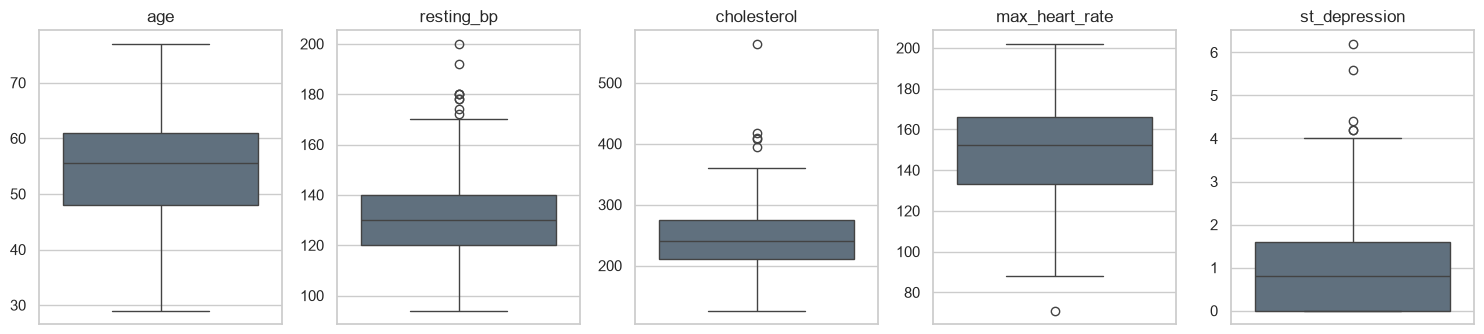

age               0
resting_bp        9
cholesterol       5
max_heart_rate    1
st_depression     5
Name: outlier_rows, dtype: int64

In [11]:
numeric = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
for ax, col in zip(axes, numeric):
    sns.boxplot(y=df[col], ax=ax, color=NO_DISEASE)
    ax.set_title(col)
    ax.set_ylabel("")
save(fig, "01_outliers_boxplots")

q1, q3 = df[numeric].quantile(0.25), df[numeric].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numeric] < q1 - 1.5 * iqr) | (df[numeric] > q3 + 1.5 * iqr)).sum()
outliers.rename("outlier_rows")

### Answer to Problem 1
**Yes, after cleaning. But the file could not be used as it came.**

* **Complete:** there are no missing values.
* **Duplicates:** 1 duplicate patient, which we removed. This leaves **302 unique patients**.
* **Invalid codes:** 6 cells hold codes outside the documented range (`ca = 4` for 4 patients, `thal = 0` for 2). These were missing values in the source, so we keep the patients and label the cells *Unknown*.
* **Critical finding: the outcome label is reversed.** In this file `target = 1` means *no* heart disease. The chest-pain, ECG and slope codes are also documented wrongly. Without this check, every conclusion below would have pointed the wrong way, for example that women and younger patients are at higher risk.
* **Outliers:** a few extreme values exist, such as cholesterol of 564 and blood pressure of 200. All are medically possible, so we keep them and flag them.

**Business recommendation:** publish a validated data dictionary and add an automated check on code ranges and label counts before any report goes out.

## 4. Feature engineering
To make the analysis easier to read, we group the raw numbers into **clinically meaningful bands**:
* **Age groups:** 10-year bands.
* **Blood pressure:** the American Heart Association (AHA) stages.
* **Cholesterol:** the US National Cholesterol Education Program (NCEP) bands.
* **Maximum heart rate:** bands of 20 beats per minute.
* **ST depression:** bands of increasing severity.

In [12]:
df["age_group"] = pd.cut(df["age"], [0, 40, 50, 60, 70, 120], right=False,
                         labels=["Under 40", "40-49", "50-59", "60-69", "70+"])
df["bp_category"] = pd.cut(df["resting_bp"], [0, 120, 130, 140, 400], right=False,
                           labels=["Normal (<120)", "Elevated (120-129)", "Stage 1 (130-139)", "Stage 2 (140+)"])
df["cholesterol_category"] = pd.cut(df["cholesterol"], [0, 200, 240, 1000], right=False,
                                    labels=["Desirable (<200)", "Borderline (200-239)", "High (240+)"])
df["max_hr_band"] = pd.cut(df["max_heart_rate"], [0, 120, 140, 160, 250], right=False,
                           labels=["Under 120", "120-139", "140-159", "160+"])
df["st_depression_band"] = pd.cut(df["st_depression"], [-0.1, 0, 1, 2, 10],
                                  labels=["None (0)", "Mild (0.1-1)", "Moderate (1.1-2)", "Severe (>2)"])
df["vessels_label"] = df["vessels_blocked"].map(lambda v: "Unknown" if pd.isna(v) else f"{int(v)} vessel(s)")

# Fixed order for categorical text columns so charts read logically
order = {
    "chest_pain_type": ["Typical angina", "Atypical angina", "Non-anginal pain", "Asymptomatic"],
    "resting_ecg": ["Normal", "ST-T abnormality", "LV hypertrophy"],
    "st_slope": ["Upsloping", "Flat", "Downsloping"],
    "thallium_result": ["Normal", "Fixed defect", "Reversible defect", "Unknown"],
}
for col, cats in order.items():
    df[col] = pd.Categorical(df[col], categories=cats, ordered=True)

df[["age", "age_group", "resting_bp", "bp_category", "cholesterol", "cholesterol_category"]].head()

,age,age_group,resting_bp,bp_category,cholesterol,cholesterol_category
0,63,60-69,145,Stage 2 (140+),233,Borderline (200-239)
1,37,Under 40,130,Stage 1 (130-139),250,High (240+)
2,41,40-49,130,Stage 1 (130-139),204,Borderline (200-239)
3,56,50-59,120,Elevated (120-129),236,Borderline (200-239)
4,57,50-59,120,Elevated (120-129),354,High (240+)


## 5. Business Problem 2: How big is the problem, and who are our patients?

In [13]:
OVERALL_RATE = df["heart_disease"].mean() * 100
kpis = pd.Series({
    "Patients": len(df),
    "With heart disease": int(df["heart_disease"].sum()),
    "Disease rate (%)": round(OVERALL_RATE, 1),
    "Median age": df["age"].median(),
    "Men (%)": round((df["sex"] == "Male").mean() * 100, 1),
})
kpis

Patients              302.0
With heart disease    138.0
Disease rate (%)       45.7
Median age             55.5
Men (%)                68.2
dtype: float64

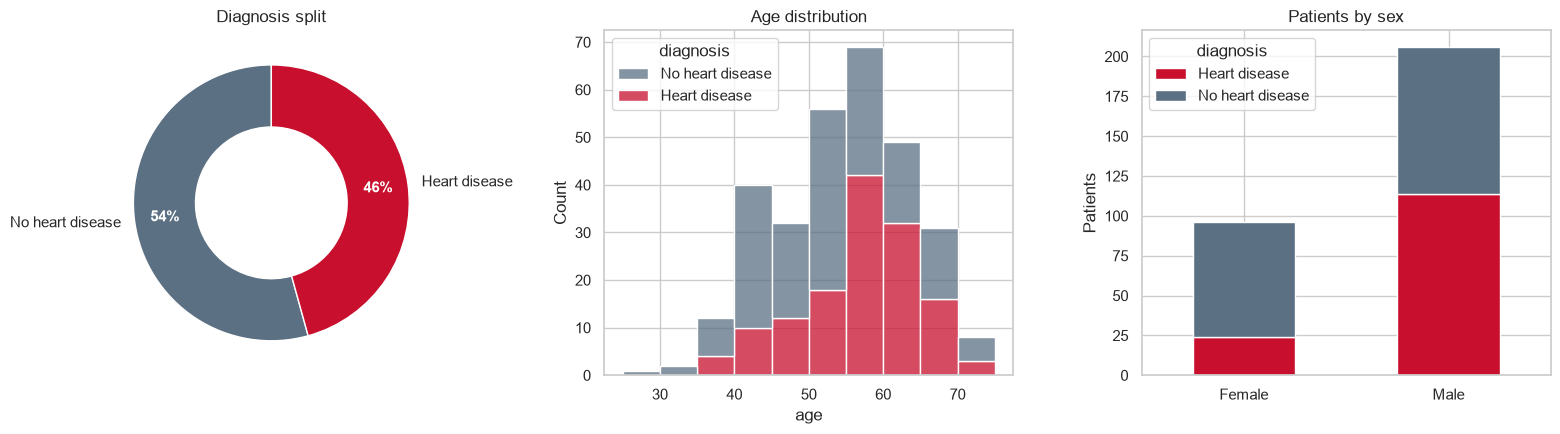

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

counts = df["diagnosis"].value_counts()
_, _, pct_labels = axes[0].pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90,
            colors=[NO_DISEASE if k == "No heart disease" else DISEASE for k in counts.index],
            wedgeprops={"width": 0.45}, pctdistance=0.78, textprops={"fontsize": 11})
plt.setp(pct_labels, color="white", fontweight="bold")
axes[0].set_title("Diagnosis split")

sns.histplot(data=df, x="age", hue="diagnosis", bins=range(25, 80, 5), multiple="stack",
             palette={"Heart disease": DISEASE, "No heart disease": NO_DISEASE}, ax=axes[1])
axes[1].set_title("Age distribution")

sex_counts = df.groupby(["sex", "diagnosis"]).size().unstack()
sex_counts.plot(kind="bar", stacked=True, color=[DISEASE, NO_DISEASE], ax=axes[2], rot=0)
axes[2].set(title="Patients by sex", xlabel="", ylabel="Patients")
save(fig, "02_patient_profile")

### Answer to Problem 2
* **138 of 302 patients (46%) have heart disease.** That is almost half of everyone referred, so cardiology capacity should plan for roughly one confirmed case in every two referrals.
* **The typical patient is a man in his mid-50s.** The median age is 55.5 and 68% of patients are men. Women are under-represented: only 96 of the 302.

**Business recommendation:** use 46% as the baseline. Any group well above it is a priority, and any group well below it may be over-referred.

## 6. Business Problem 3: Which age groups are most affected?

,patients,with_disease,disease_rate_%
age_group,,,
Under 40,15,4,26.7
40-49,72,22,30.6
50-59,125,60,48.0
60-69,80,48,60.0
70+,10,4,40.0


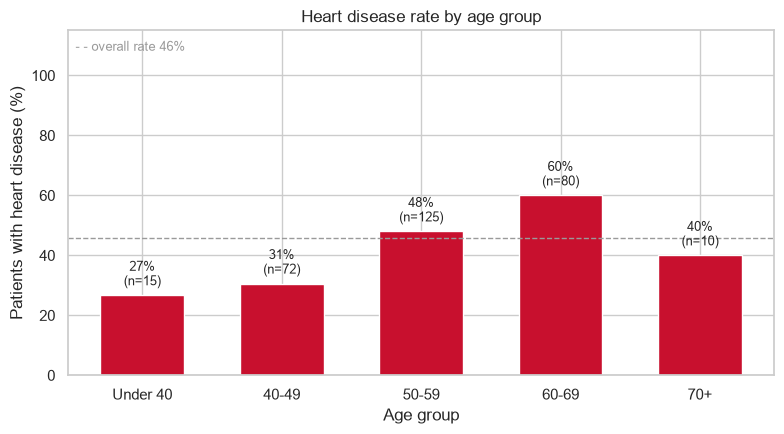

In [15]:
age_t = rate_table(df, "age_group")
display(age_t)
plot_rate(age_t, "Heart disease rate by age group", "Age group", "03_rate_by_age")

In [16]:
# Are patients with heart disease older on average? (Mann-Whitney U test)
ages_d, ages_n = df.loc[df.heart_disease == 1, "age"], df.loc[df.heart_disease == 0, "age"]
p = stats.mannwhitneyu(ages_d, ages_n).pvalue
print(f"Median age - disease: {ages_d.median():.0f}, no disease: {ages_n.median():.0f}  (p = {p:.4f})")

Median age - disease: 58, no disease: 52  (p = 0.0000)


### Answer to Problem 3
* The disease rate **rises steadily with age**: 27% under 40, 31% at 40–49, 48% at 50–59 and **60% at 60–69**.
* Patients with heart disease are older: a median of **58 years against 52** (Mann–Whitney test, p < 0.001).
* The 70+ group shows 40%, but it holds only 10 patients, which is too few to draw a conclusion.

**Business recommendation:** **age 50 is the tipping point.** Below it, rates sit well under the 46% average. Make 50+ the trigger for routine cardiac screening, and treat 60–69 as the highest-yield age band.

## 7. Business Problem 4: Do men and women differ?

,patients,with_disease,disease_rate_%
sex,,,
Female,96,24,25.0
Male,206,114,55.3


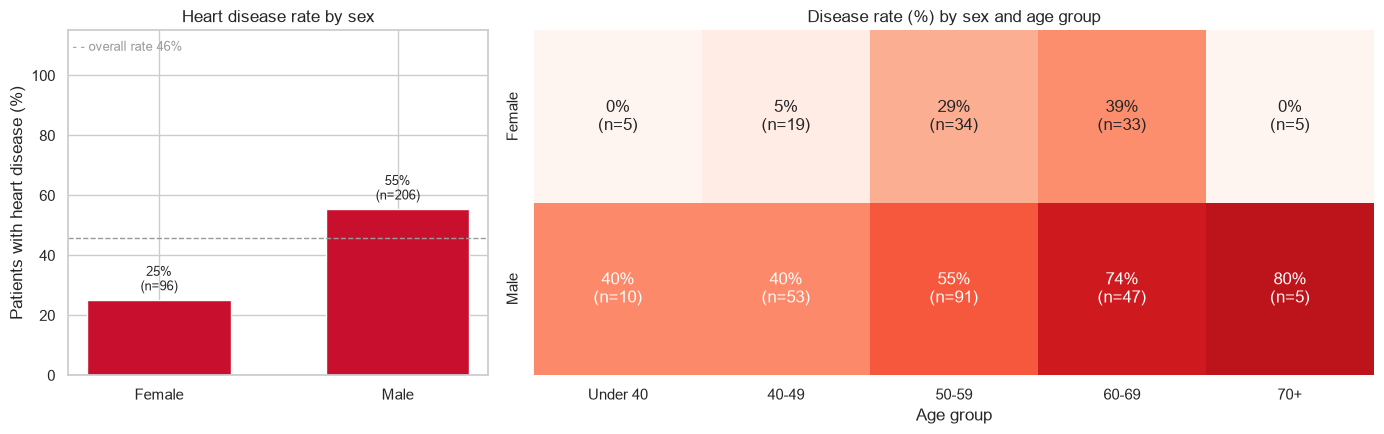

Chi-square test, sex vs diagnosis: p = 0.000002


In [17]:
sex_t = rate_table(df, "sex")
display(sex_t)

# Sex x age: rate and patient count side by side
sex_age = df.pivot_table(index="sex", columns="age_group", values="heart_disease", aggfunc="mean", observed=True).mul(100).round(0)
sex_age_n = df.pivot_table(index="sex", columns="age_group", values="heart_disease", aggfunc="count", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
plot_rate(sex_t, "Heart disease rate by sex", "", None, ax=axes[0])
sns.heatmap(sex_age, annot=sex_age.astype(int).astype(str) + "%\n(n=" + sex_age_n.astype(str) + ")",
            fmt="", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=axes[1])
axes[1].set(title="Disease rate (%) by sex and age group", xlabel="Age group", ylabel="")
save(fig, "04_rate_by_sex_and_age")

chi_p = stats.chi2_contingency(pd.crosstab(df["sex"], df["heart_disease"]))[1]
print(f"Chi-square test, sex vs diagnosis: p = {chi_p:.6f}")

### Answer to Problem 4
* **Men are more than twice as likely to have heart disease: 55% against 25% for women** (chi-square, p < 0.001).
* The gap holds at every age. For men the rate climbs from 40% under 50 to **74% at 60–69**. For women it stays low until 50 and then rises to 39% at 60–69.
* Women make up only 32% of patients, so the department may be **under-referring women**, whose symptoms are often less typical.

**Business recommendation:** run screening for men from age 40–45 and for women from age 50, the usual post-menopause rise. Also review whether women with symptoms are being referred as often as men.

## 8. Business Problem 5: Can chest-pain type be used to triage patients?

,patients,with_disease,disease_rate_%
chest_pain_type,,,
Typical angina,23,7,30.4
Atypical angina,50,9,18.0
Non-anginal pain,86,18,20.9
Asymptomatic,143,104,72.7


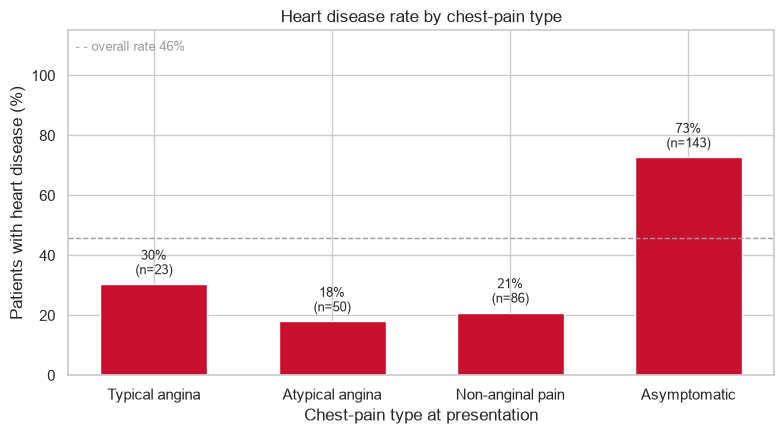

In [18]:
cp_t = rate_table(df, "chest_pain_type")
display(cp_t)
plot_rate(cp_t, "Heart disease rate by chest-pain type", "Chest-pain type at presentation", "05_rate_by_chest_pain")

### Answer to Problem 5
**Yes. This is the most surprising and most useful finding.**
* Patients with **no chest pain (asymptomatic) have the highest rate: 73%**, and they make up 143 of 302 patients.
* Patients with classic **typical angina are only at 30%**, and those with atypical or non-anginal pain are at about 18–21%.

**Business recommendation:** a triage rule of "chest pain = urgent" would miss most cases. **Silent (asymptomatic) presentations should be fast-tracked to further tests**, especially in men over 50. Add this to the triage protocol and staff training.

## 9. Business Problem 6: Do routine checks separate patients?
Routine checks are cheap and done for almost everyone: **blood pressure, cholesterol, fasting blood sugar and the resting ECG**.

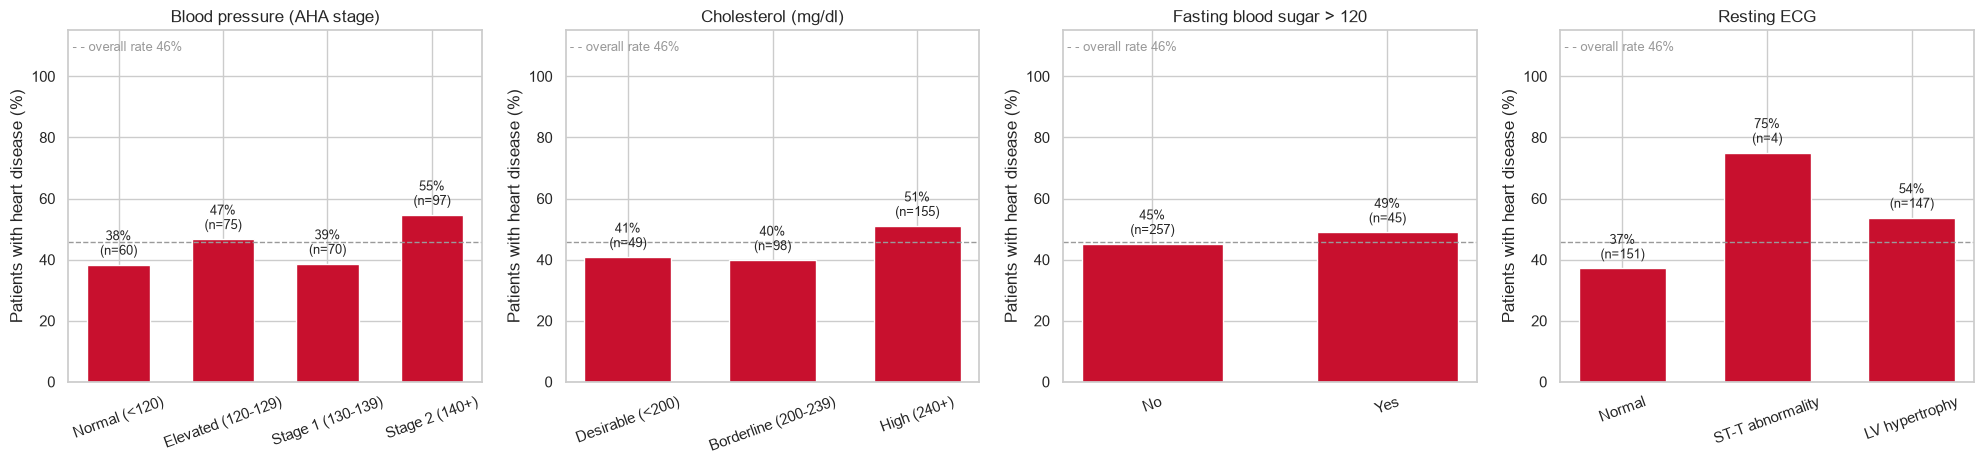

diagnosis,Heart disease,No heart disease,p_value
resting_bp,134.4,129.2,0.032
cholesterol,251.1,242.6,0.042


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
routine = [("bp_category", "Blood pressure (AHA stage)"), ("cholesterol_category", "Cholesterol (mg/dl)"),
           ("high_fasting_sugar", "Fasting blood sugar > 120"), ("resting_ecg", "Resting ECG")]
routine_tables = {}
for ax, (col, label) in zip(axes, routine):
    routine_tables[col] = rate_table(df, col)
    plot_rate(routine_tables[col], label, "", None, ax=ax)
    ax.tick_params(axis="x", labelrotation=20)
save(fig, "06_rate_by_routine_checks")

# Do the averages differ between the two groups?
means = df.groupby("diagnosis")[["resting_bp", "cholesterol"]].mean().round(1).T
means["p_value"] = [stats.mannwhitneyu(df.loc[df.heart_disease == 1, c], df.loc[df.heart_disease == 0, c]).pvalue
                    for c in means.index]
means.round(3)

### Answer to Problem 6
**Only weakly. Routine checks are poor at separating patients on their own.**
* **Blood pressure:** 55% at Stage 2 (140+) against 38% for normal, but the pattern is not consistent and not statistically significant across bands.
* **Cholesterol:** 51% for high (240+) against 41% for desirable, also not significant across bands. Average values differ only slightly: BP 134 against 129, cholesterol 251 against 243.
* **Fasting blood sugar:** no difference (49% against 45%).
* **Resting ECG:** a modest signal. Normal ECG is 37% and LV hypertrophy is 54%.

**Business recommendation:** keep routine checks for general cardiovascular prevention, but **don't use them as the gate for specialist referral.** A normal cholesterol or blood pressure result should not reassure staff.

## 10. Business Problem 7: How useful is the exercise stress test?
The stress test records four things:
* **Maximum heart rate** reached.
* **Exercise angina:** chest pain during exercise.
* **ST depression:** a dip on the ECG.
* **ST slope:** the shape of the ECG at peak exercise.

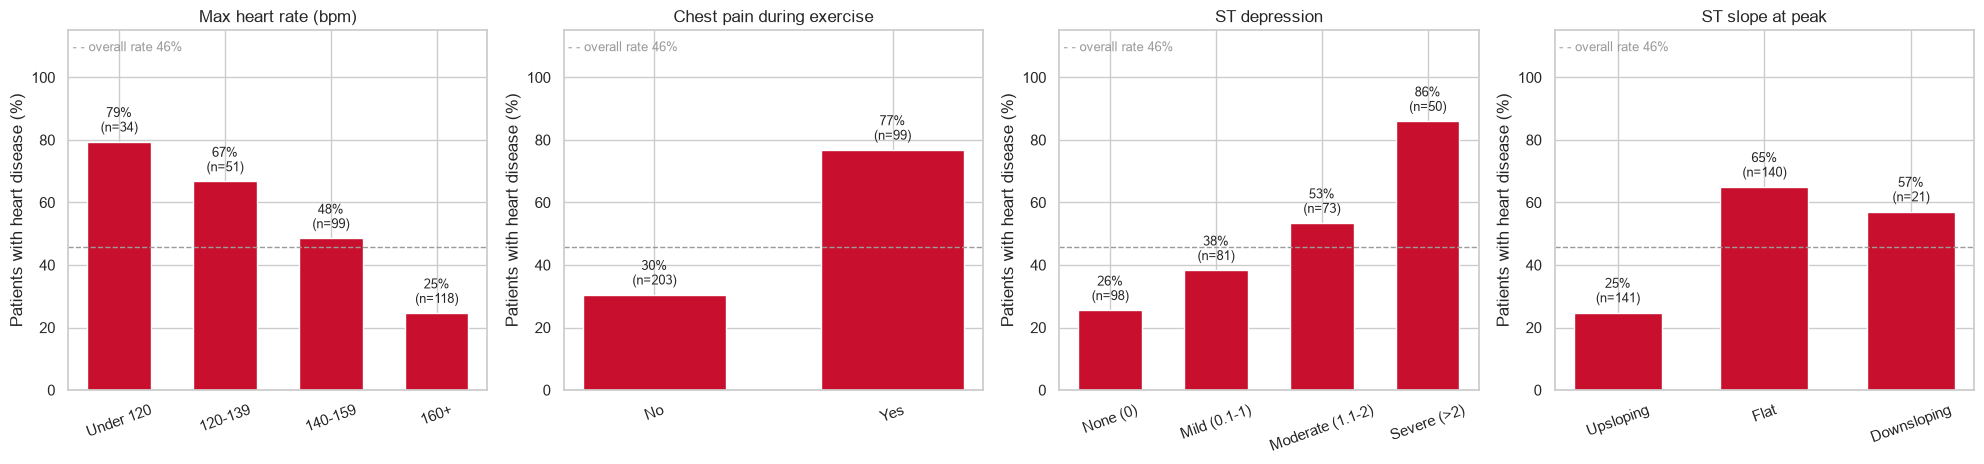

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
stress = [("max_hr_band", "Max heart rate (bpm)"), ("exercise_angina", "Chest pain during exercise"),
          ("st_depression_band", "ST depression"), ("st_slope", "ST slope at peak")]
for ax, (col, label) in zip(axes, stress):
    plot_rate(rate_table(df, col), label, "", None, ax=ax)
    ax.tick_params(axis="x", labelrotation=20)
save(fig, "07_rate_by_stress_test")

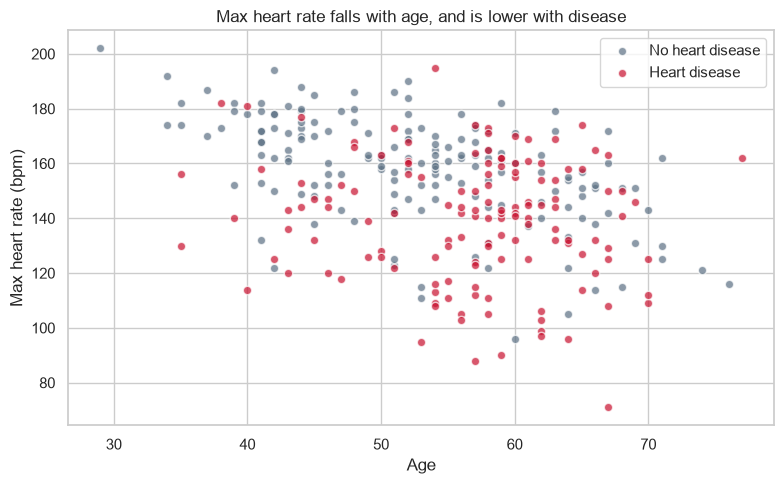

In [21]:
# Max heart rate vs age, coloured by diagnosis
fig, ax = plt.subplots(figsize=(8, 5))
for value, colour, name in [(0, NO_DISEASE, "No heart disease"), (1, DISEASE, "Heart disease")]:
    sub = df[df.heart_disease == value]
    ax.scatter(sub["age"], sub["max_heart_rate"], c=colour, alpha=0.7, label=name, edgecolor="white")
ax.set(xlabel="Age", ylabel="Max heart rate (bpm)", title="Max heart rate falls with age, and is lower with disease")
ax.legend()
save(fig, "07b_age_vs_max_hr")

### Answer to Problem 7
**It is very useful. All four stress-test measures show strong, consistent patterns.**
* **Max heart rate:** 79% disease when it stays under 120 bpm, and 25% when it reaches 160+.
* **Chest pain during exercise:** 77% with it, 31% without.
* **ST depression:** the rate rises from 26% (none) to **86% (severe, >2)**.
* **ST slope:** flat or downsloping is 57–65%, against 25% for upsloping.

**Business recommendation:** the stress test is the **best value mid-cost test**. Offer it early to patients with silent chest pain or who are aged 50+.

## 11. Business Problem 8: How useful are imaging tests?
There are two imaging tests:
* **Fluoroscopy** counts the major vessels with visible narrowing (0–3).
* The **thallium stress scan** shows how blood reaches the heart muscle.

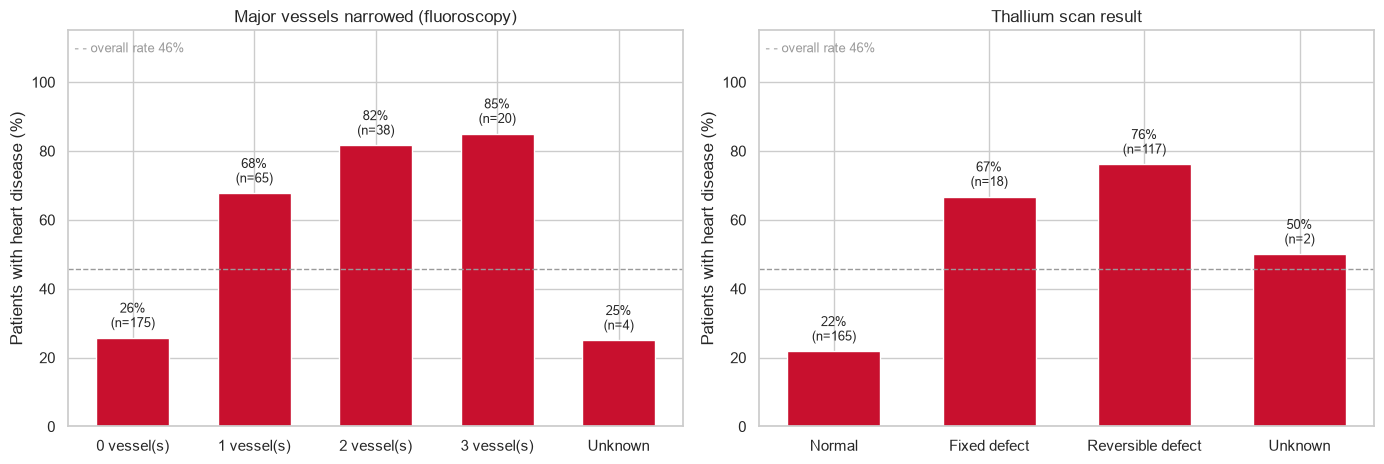

,patients,with_disease,disease_rate_%
vessels_label,,,
0 vessel(s),175,45,25.7
1 vessel(s),65,44,67.7
2 vessel(s),38,31,81.6
3 vessel(s),20,17,85.0
Unknown,4,1,25.0


,patients,with_disease,disease_rate_%
thallium_result,,,
Normal,165,36,21.8
Fixed defect,18,12,66.7
Reversible defect,117,89,76.1
Unknown,2,1,50.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
vessels_t = rate_table(df, "vessels_label")
thal_t = rate_table(df, "thallium_result")
plot_rate(vessels_t, "Major vessels narrowed (fluoroscopy)", "", None, ax=axes[0])
plot_rate(thal_t, "Thallium scan result", "", None, ax=axes[1])
save(fig, "08_rate_by_imaging")
display(vessels_t, thal_t)

### Answer to Problem 8
**Imaging gives the strongest signal of all.**
* **Fluoroscopy:** the disease rate climbs with each narrowed vessel, from 26% at 0 to 68% at 1, 82% at 2 and **85% at 3**.
* **Thallium scan:** a normal result means 22% disease, while a **reversible defect means 76%** and a fixed defect 67%.

**Business recommendation:** imaging is expensive, so **reserve it for patients whose stress test or symptoms already point to disease** (see the risk tiers in Problem 10). In this group the tests change decisions most.

## 12. Business Problem 9: Which factors matter most?
To compare very different factors on one scale, we use **Cramér's V**. It measures how strongly a factor is linked to the diagnosis, from 0 (no link) to 1 (perfect link). Numeric measurements are compared using the bands built in section 4.

We also report the **rate gap**. This is the difference, in percentage points, between the highest-risk and the lowest-risk group. Business users usually find it easier to read.

In [23]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p

factors = {
    "Thallium scan": ("thallium_result", "Imaging"), "Vessels narrowed": ("vessels_label", "Imaging"),
    "Chest-pain type": ("chest_pain_type", "Symptoms"), "Exercise angina": ("exercise_angina", "Stress test"),
    "ST depression": ("st_depression_band", "Stress test"), "Max heart rate": ("max_hr_band", "Stress test"),
    "ST slope": ("st_slope", "Stress test"), "Sex": ("sex", "Demographics"), "Age group": ("age_group", "Demographics"),
    "Resting ECG": ("resting_ecg", "Routine check"), "Blood pressure": ("bp_category", "Routine check"),
    "Cholesterol": ("cholesterol_category", "Routine check"), "Fasting blood sugar": ("high_fasting_sugar", "Routine check"),
}
rows = []
for name, (col, group) in factors.items():
    sub = df[df[col].astype(str) != "Unknown"]
    v, p = cramers_v(sub[col], sub["heart_disease"])
    rates = rate_table(sub, col).query("patients >= 10")["disease_rate_%"]   # ignore tiny groups
    rows.append([name, group, round(v, 2), round(rates.max() - rates.min(), 1), p])
ranking = (pd.DataFrame(rows, columns=["factor", "test_type", "cramers_v", "rate_gap_pts", "p_value"])
           .sort_values("cramers_v", ascending=False).reset_index(drop=True))
ranking["significant"] = np.where(ranking["p_value"] < 0.05, "Yes", "No")
ranking.index += 1
ranking

,factor,test_type,cramers_v,rate_gap_pts,p_value,significant
1,Thallium scan,Imaging,0.53,54.3,4.251403e-19,Yes
2,Chest-pain type,Symptoms,0.52,54.7,1.892684e-17,Yes
3,Vessels narrowed,Imaging,0.49,59.3,1.010088e-15,Yes
4,Exercise angina,Stress test,0.43,46.3,9.556466e-14,Yes
5,ST depression,Stress test,0.42,60.5,2.486390e-11,Yes
6,Max heart rate,Stress test,0.39,54.8,5.310594e-10,Yes
7,ST slope,Stress test,0.39,40.2,6.577783e-11,Yes
8,Sex,Demographics,0.28,30.3,1.550855e-06,Yes
9,Age group,Demographics,0.23,33.3,3.249459e-03,Yes
10,Resting ECG,Routine check,0.18,16.6,7.713053e-03,Yes


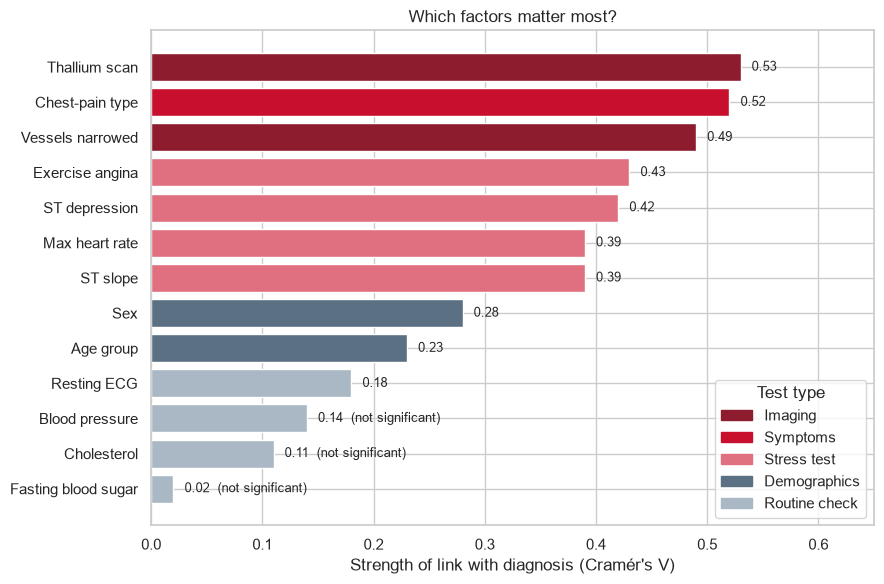

In [24]:
colours = {"Imaging": "#8C1C2E", "Symptoms": DISEASE, "Stress test": "#E0707F", "Demographics": NO_DISEASE, "Routine check": "#A9B8C4"}
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = ranking.iloc[::-1]
ax.barh(plot_df["factor"], plot_df["cramers_v"], color=plot_df["test_type"].map(colours))
for i, (v, sig) in enumerate(zip(plot_df["cramers_v"], plot_df["significant"])):
    ax.text(v + 0.01, i, f"{v:.2f}" + ("" if sig == "Yes" else "  (not significant)"), va="center", fontsize=9)
ax.set(xlabel="Strength of link with diagnosis (Cramér's V)", title="Which factors matter most?", xlim=(0, 0.65))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles, colours.keys(), loc="lower right", title="Test type")
save(fig, "09_factor_ranking")

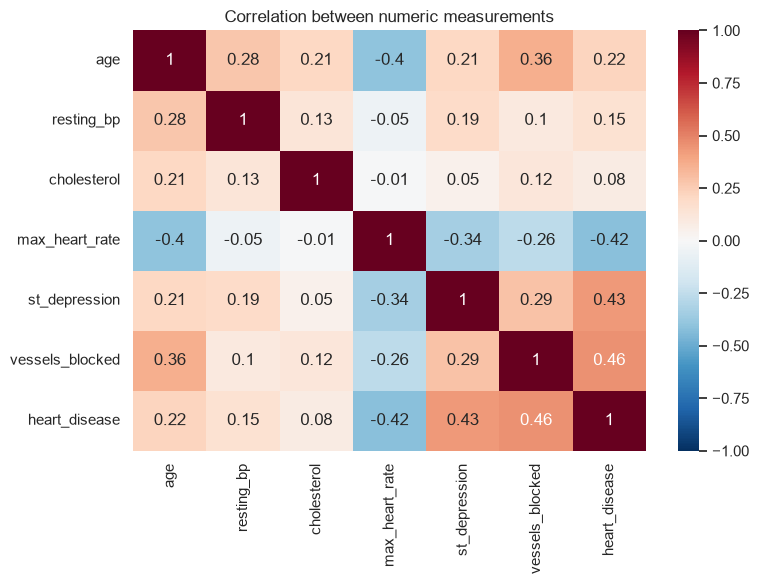

In [25]:
# Correlation heatmap for the numeric measurements (for completeness)
corr = df[["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "vessels_blocked", "heart_disease"]].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric measurements")
save(fig, "09b_correlation_heatmap")

### Answer to Problem 9
Ranked by strength of link with the diagnosis:
1. **Thallium scan (0.53)**, **chest-pain type (0.52)** and **vessels narrowed (0.49)**: strong.
2. **Stress test measures (0.39–0.43)**: exercise angina, ST depression, max heart rate, ST slope.
3. **Sex (0.28)** and **age (0.23)**: moderate.
4. **Routine checks (0.02–0.18)**: weak. Blood pressure, cholesterol and blood sugar are not statistically significant.

**Business recommendation:** focus the diagnostic budget on **symptom assessment, then the stress test, then targeted imaging**. Cholesterol and blood sugar results add little to the decision of whether a referred patient has heart disease.

## 13. Business Problem 10: Can we segment patients into risk tiers?
We count **six clinical warning signs** from Problems 5–8. Each sign adds one point:

| Warning sign | Rule |
|---|---|
| Silent chest pain | `chest_pain_type` = Asymptomatic |
| Exercise angina | `exercise_angina` = Yes |
| ST depression | `st_depression` > 1 |
| Low max heart rate | `max_heart_rate` < 140 |
| Narrowed vessels | `vessels_blocked` ≥ 1 |
| Thallium defect | `thallium_result` = Fixed or Reversible defect |

The tiers are: **0–1 signs = Low**, **2–3 = Medium**, **4–6 = High**.

> This is a **descriptive** segmentation, not a validated clinical score. The signs were chosen from this same data, so the tiers must be tested on new patients before real use.

,patients,with_disease,disease_rate_%
warning_signs,,,
0,53,2,3.8
1,69,13,18.8
2,59,16,27.1
3,29,21,72.4
4,44,40,90.9
5,30,28,93.3
6,18,18,100.0


,patients,with_disease,disease_rate_%,share_of_patients_%,share_of_all_disease_%
risk_tier,,,,,
Low,122,15,12.3,40.4,10.9
Medium,88,37,42.0,29.1,26.8
High,92,86,93.5,30.5,62.3


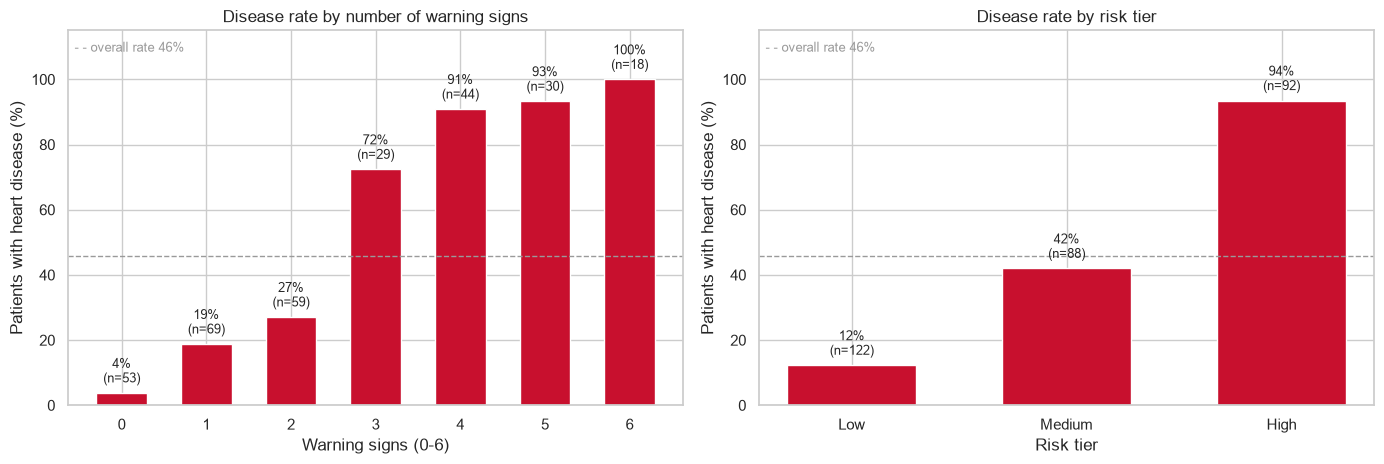

In [26]:
signs = pd.DataFrame({
    "sign_silent_chest_pain": df["chest_pain_type"] == "Asymptomatic",
    "sign_exercise_angina": df["exercise_angina"] == "Yes",
    "sign_st_depression": df["st_depression"] > 1,
    "sign_low_max_hr": df["max_heart_rate"] < 140,
    "sign_vessels_narrowed": df["vessels_blocked"].fillna(0) >= 1,
    "sign_thallium_defect": df["thallium_result"].isin(["Fixed defect", "Reversible defect"]),
}).astype(int)
df = pd.concat([df, signs], axis=1)
df["warning_signs"] = signs.sum(axis=1)
df["risk_tier"] = pd.cut(df["warning_signs"], [-1, 1, 3, 6], labels=["Low", "Medium", "High"])

signs_t = rate_table(df, "warning_signs")
tier_t = rate_table(df, "risk_tier")
tier_t["share_of_patients_%"] = (tier_t["patients"] / len(df) * 100).round(1)
tier_t["share_of_all_disease_%"] = (tier_t["with_disease"] / df["heart_disease"].sum() * 100).round(1)
display(signs_t, tier_t)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_rate(signs_t, "Disease rate by number of warning signs", "Warning signs (0-6)", None, ax=axes[0])
plot_rate(tier_t, "Disease rate by risk tier", "Risk tier", None, ax=axes[1])
save(fig, "10_risk_tiers")

### Answer to Problem 10
**Yes. A simple count of six warning signs splits patients into clearly different groups.**

| Tier | Patients | Disease rate | Share of all disease cases |
|---|---|---|---|
| Low (0–1 signs) | 122 (40%) | **12%** | 11% |
| Medium (2–3 signs) | 88 (29%) | **42%** | 27% |
| High (4–6 signs) | 92 (30%) | **93%** | 62% |

* The rate jumps sharply at **3 or more signs** (72%+).
* The **High tier holds 62% of all disease cases in just 30% of patients**.

**Business recommendation:**
* **High:** book a specialist review within days.
* **Medium:** schedule a stress test or imaging.
* **Low:** offer routine follow-up and prevention advice.

Validate the tiers on new patients before clinical use.

## 14. Export for Power BI
We export four tables to `data/processed/`:

| File | Contents |
|---|---|
| `heart_disease_clean.csv` | One row per patient, with readable labels, bands, warning signs, risk tier and sort-order columns. This is the Power BI fact table |
| `factor_ranking.csv` | The ranking from Problem 9 |
| `data_quality_log.csv` | What was found and fixed in Problem 1 |
| `data_dictionary.csv` | The meaning of every column in the clean file |

In [27]:
export_cols = ["patient_id", "age", "age_group", "sex", "chest_pain_type", "resting_bp", "bp_category",
               "cholesterol", "cholesterol_category", "high_fasting_sugar", "resting_ecg", "max_heart_rate",
               "max_hr_band", "exercise_angina", "st_depression", "st_depression_band", "st_slope",
               "vessels_blocked", "vessels_label", "thallium_result", *signs.columns, "warning_signs", "risk_tier",
               "heart_disease", "diagnosis", "original_target"]
# Power BI sorts text alphabetically ("70+" before "Under 40"), so export a sort-order number for each banded column
sort_cols = []
for col in ["age_group", "bp_category", "cholesterol_category", "max_hr_band", "st_depression_band",
            "chest_pain_type", "resting_ecg", "st_slope", "thallium_result", "risk_tier"]:
    df[f"{col}_order"] = df[col].cat.codes + 1
    sort_cols.append(f"{col}_order")
export = df[export_cols + sort_cols].copy()
export["vessels_blocked"] = export["vessels_blocked"].astype("Int64")   # whole numbers; blank = unknown
export.to_csv(PROCESSED / "heart_disease_clean.csv", index=False)
ranking.rename_axis("rank").to_csv(PROCESSED / "factor_ranking.csv")

quality_log = pd.DataFrame([
    ["Duplicate rows", 1, "Removed duplicate patient record", "302 unique patients"],
    ["Invalid 'ca' = 4", int((raw.drop_duplicates()["ca"] == 4).sum()), "Set to missing ('Unknown')", "Was '?' in UCI source"],
    ["Invalid 'thal' = 0", int((raw["thal"] == 0).sum()), "Set to missing ('Unknown')", "Was '?' in UCI source"],
    ["Reversed outcome label", len(df), "heart_disease = 1 - target", "Confirmed against UCI counts"],
    ["Mis-documented codes (cp, restecg, slope, thal)", len(df), "Re-labelled using UCI mapping", "Confirmed against UCI counts"],
    ["Outliers (IQR rule)", int(outliers.sum()), "Kept and flagged", "All medically possible"],
], columns=["issue", "rows_affected", "action", "note"])
quality_log.to_csv(PROCESSED / "data_quality_log.csv", index=False)

dictionary = pd.DataFrame([
    ["patient_id", "Unique patient key"], ["age", "Age in years"], ["age_group", "10-year age band"],
    ["sex", "Male / Female"], ["chest_pain_type", "Typical angina, Atypical angina, Non-anginal pain, Asymptomatic"],
    ["resting_bp", "Resting blood pressure (mm Hg)"], ["bp_category", "AHA blood pressure stage"],
    ["cholesterol", "Serum cholesterol (mg/dl)"], ["cholesterol_category", "NCEP cholesterol band"],
    ["high_fasting_sugar", "Fasting blood sugar > 120 mg/dl (Yes/No)"], ["resting_ecg", "Resting ECG result"],
    ["max_heart_rate", "Maximum heart rate in stress test (bpm)"], ["max_hr_band", "Max heart rate band"],
    ["exercise_angina", "Chest pain during exercise (Yes/No)"], ["st_depression", "ST depression on exercise ECG"],
    ["st_depression_band", "ST depression severity band"], ["st_slope", "Slope of peak exercise ST segment"],
    ["vessels_blocked", "Major vessels narrowed on fluoroscopy (0-3, blank = unknown)"],
    ["vessels_label", "Vessels as text, incl. Unknown"], ["thallium_result", "Thallium scan result"],
    ["sign_*", "1 if the warning sign is present (see Problem 10)"], ["warning_signs", "Number of warning signs (0-6)"],
    ["risk_tier", "Low (0-1), Medium (2-3), High (4-6)"], ["heart_disease", "1 = heart disease, 0 = none (corrected)"],
    ["diagnosis", "Heart disease / No heart disease"], ["original_target", "Original label from the raw file (1 = no disease)"],
    ["*_order", "Sort-order number for the matching text column (use 'Sort by column' in Power BI)"],
], columns=["column", "description"])
dictionary.to_csv(PROCESSED / "data_dictionary.csv", index=False)

print("Exported:", *[p.name for p in sorted(PROCESSED.glob("*.csv"))], sep="\n  ")

Exported:
  data_dictionary.csv
  data_quality_log.csv
  factor_ranking.csv
  heart_disease_clean.csv


In [28]:
summary = {
    "patients": len(df), "with_disease": int(df.heart_disease.sum()), "overall_rate": round(OVERALL_RATE, 1),
    "median_age": float(df.age.median()), "men_pct": round((df.sex == "Male").mean() * 100, 1),
    "age": age_t["disease_rate_%"].to_dict(), "age_n": age_t["patients"].to_dict(),
    "sex": sex_t["disease_rate_%"].to_dict(), "sex_n": sex_t["patients"].to_dict(),
    "sex_age": {s: sex_age.loc[s].to_dict() for s in sex_age.index},
    "chest_pain": cp_t["disease_rate_%"].to_dict(), "chest_pain_n": cp_t["patients"].to_dict(),
    "routine": {c: t["disease_rate_%"].to_dict() for c, t in routine_tables.items()},
    "routine_n": {c: t["patients"].to_dict() for c, t in routine_tables.items()},
    "stress": {c: rate_table(df, c)["disease_rate_%"].to_dict() for c, _ in stress},
    "stress_n": {c: rate_table(df, c)["patients"].to_dict() for c, _ in stress},
    "vessels": vessels_t["disease_rate_%"].to_dict(), "vessels_n": vessels_t["patients"].to_dict(),
    "thal": thal_t["disease_rate_%"].to_dict(), "thal_n": thal_t["patients"].to_dict(),
    "ranking": ranking[["factor", "test_type", "cramers_v", "rate_gap_pts", "significant"]].to_dict("records"),
    "signs": signs_t["disease_rate_%"].to_dict(), "signs_n": signs_t["patients"].to_dict(),
    "tiers": tier_t.reset_index().astype({"risk_tier": str}).to_dict("records"),
    "means": means.drop(columns="p_value").to_dict(), "mean_p": means["p_value"].to_dict(),
    "outliers": outliers.to_dict(), "age_median_d": float(ages_d.median()), "age_median_n": float(ages_n.median()),
}
import json
(PROCESSED / "summary_metrics.json").write_text(json.dumps(summary, indent=1, default=str))
print("Saved summary_metrics.json")

Saved summary_metrics.json


## 15. Summary of findings
| # | Business problem | Key finding | Recommendation |
|---|---|---|---|
| 1 | Can we trust the data? | Outcome label reversed; 1 duplicate; 6 invalid codes | Validated data dictionary and automated checks |
| 2 | How big is the problem? | 46% of 302 patients have heart disease; typical patient is a man in his mid-50s | Use 46% as the baseline for comparisons |
| 3 | Which ages? | Rate climbs from 27% (<40) to 60% (60–69) | Start routine screening at 50 |
| 4 | Men vs women? | Men 55% against women 25%, at every age | Screen men from 40–45, women from 50; check under-referral of women |
| 5 | Chest-pain triage? | **Asymptomatic patients have the highest rate (73%)** | Fast-track silent presentations |
| 6 | Routine checks? | BP, cholesterol and sugar barely separate patients | Don't use them as the referral gate |
| 7 | Stress test? | Strong signals, up to 86% with severe ST depression | Best-value mid-cost test; use it early |
| 8 | Imaging? | Strongest signals (3 vessels 85%, reversible defect 76%) | Reserve for patients already flagged |
| 9 | What matters most? | Thallium, chest pain, vessels, then the stress test | Budget order: symptoms, then stress test, then targeted imaging |
| 10 | Risk tiers? | High tier: 93% disease, 62% of all cases in 30% of patients | Prioritise follow-up by tier |

**Limitations:** 302 patients from one hospital (Cleveland, 1988); observational data shows association, not causation; the risk tiers are descriptive and not clinically validated.

**Next steps:** the cleaned data feeds the Power BI dashboard (`powerbi/`) and the presentation (`presentation/`).